In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Define the column names based on the dataset format
column_names = ['user_id', 'activity', 'timestamp', 'x', 'y', 'z']

In [4]:
# Read the dataset
# The file is assumed to be in the same directory as this script
data = pd.read_csv('WISDM_ar_v1.1_raw.txt', header=None, on_bad_lines="skip", names=column_names)


In [5]:
# Convert the timestamp to datetime if necessary (it might be in nanoseconds)
data['timestamp'] = pd.to_datetime(data['timestamp'], unit='ns')
# Remove the trailing semicolon from the 'z' column
data['z'] = data['z'].str.rstrip(';').astype(float)

In [6]:
# Descriptive Statistics
print("Descriptive Statistics:")
print(data[['x', 'y', 'z']].describe())

# Class Distribution
print("\nClass Distribution:")
class_counts = data['activity'].value_counts()
total_counts = class_counts.sum()
class_percentages = (class_counts / total_counts) * 100
print(class_counts)

# Time Interval Analysis
data['time_diff'] = data['timestamp'].diff().dt.total_seconds()
print("\nTime Intervals (seconds):")
print(data['time_diff'].describe())

# Correlation Analysis
correlation_matrix = data[['x', 'y', 'z']].corr()
print("\nCorrelation Matrix:")
print(correlation_matrix)

# Outlier Detection using Z-Score
z_scores = np.abs((data[['x', 'y', 'z']] - data[['x', 'y', 'z']].mean()) / data[['x', 'y', 'z']].std())
outliers = (z_scores > 3).any(axis=1)
print("\nNumber of outliers detected:", outliers.sum())

Descriptive Statistics:
                  x             y             z
count  1.086468e+06  1.086468e+06  1.086467e+06
mean   6.641249e-01  7.246036e+00  3.977077e-01
std    6.876272e+00  6.739789e+00  4.761113e+00
min   -1.961000e+01 -1.961000e+01 -1.980000e+01
25%   -2.910000e+00  3.170000e+00 -2.220117e+00
50%    2.700000e-01  7.930000e+00  0.000000e+00
75%    4.440000e+00  1.156000e+01  2.720000e+00
max    1.995000e+01  2.004000e+01  1.961000e+01

Class Distribution:
activity
Walking       418394
Jogging       336446
Upstairs      122869
Downstairs    100426
Sitting        59939
Standing       48394
Name: count, dtype: int64

Time Intervals (seconds):
count    1.086467e+06
mean     7.595037e-02
std      1.416564e+03
min     -1.312092e+05
25%      4.968300e-02
50%      4.998800e-02
75%      5.004900e-02
max      1.970301e+05
Name: time_diff, dtype: float64

Correlation Matrix:
          x         y         z
x  1.000000  0.028560  0.067695
y  0.028560  1.000000  0.012276
z  0.06769

In [ ]:
# Plot the class distribution
plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts.index, y=class_percentages, palette='viridis')
plt.title('Distribution of Activities')
plt.xlabel('Activity')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

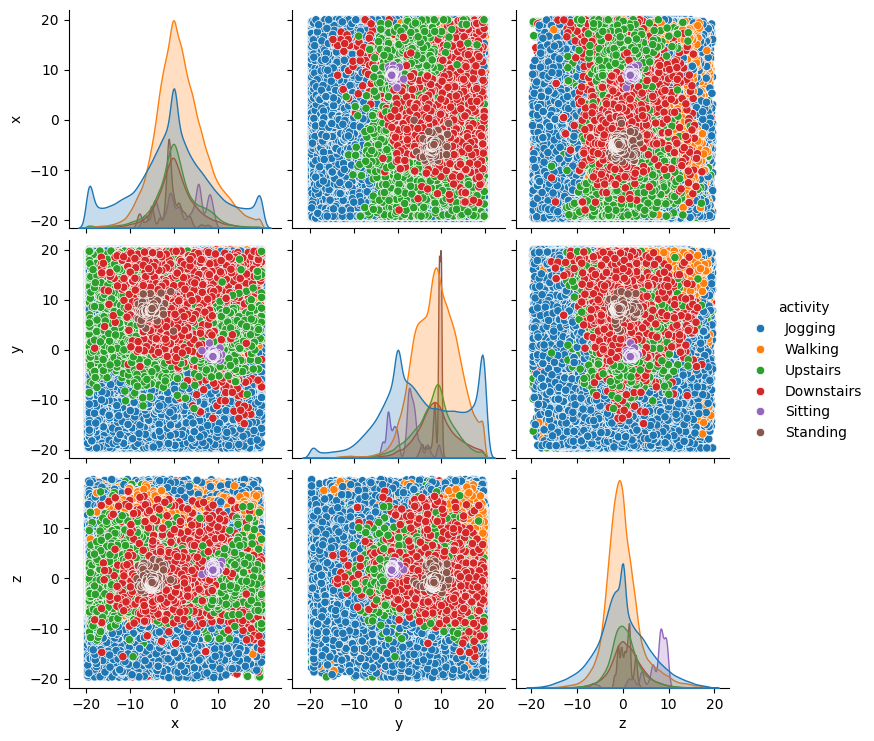

In [7]:
# Pairwise Plot
sns.pairplot(data, vars=['x', 'y', 'z'], hue='activity')
plt.show()

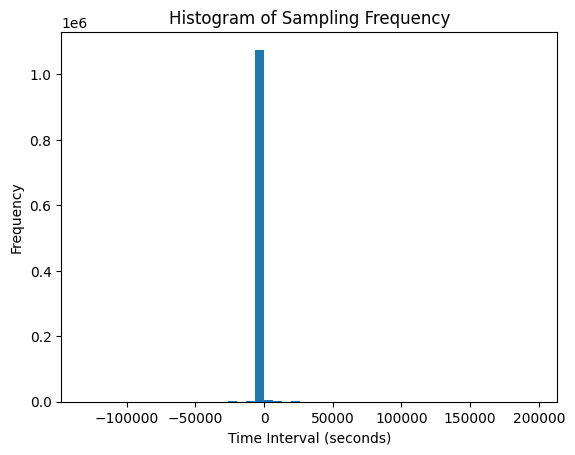

In [8]:
# Histogram of Sampling Frequency
data['time_diff'].plot(kind='hist', bins=50, title='Histogram of Sampling Frequency')
plt.xlabel('Time Interval (seconds)')
plt.show()

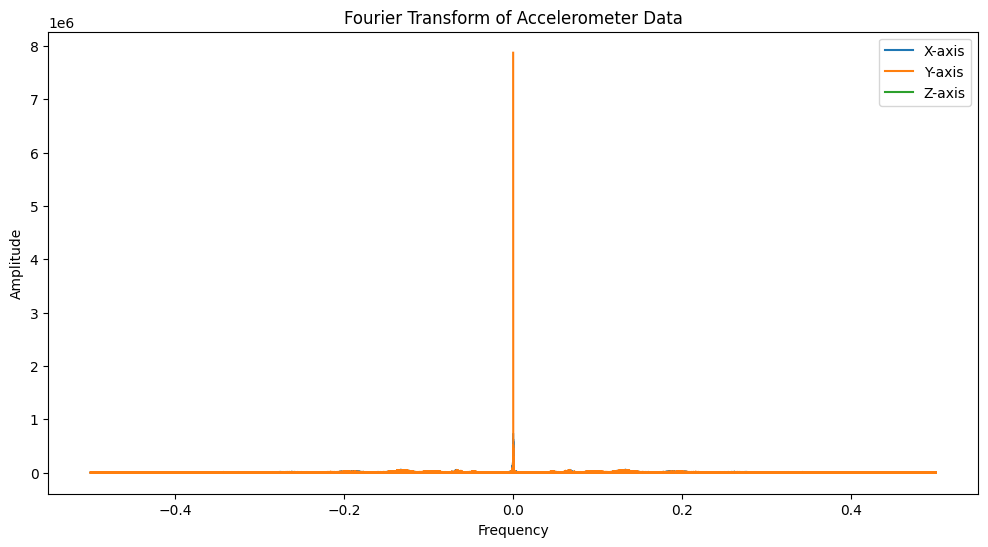

In [9]:
# Fourier Transform for Signal Analysis
fft_x = np.fft.fft(data['x'])
fft_y = np.fft.fft(data['y'])
fft_z = np.fft.fft(data['z'])
freq = np.fft.fftfreq(len(fft_x))

# Plotting the Fourier Transform
plt.figure(figsize=(12, 6))
plt.plot(freq, np.abs(fft_x), label='X-axis')
plt.plot(freq, np.abs(fft_y), label='Y-axis')
plt.plot(freq, np.abs(fft_z), label='Z-axis')
plt.title('Fourier Transform of Accelerometer Data')
plt.xlabel('Frequency')
plt.ylabel('Amplitude')
plt.legend()
plt.show()